<a href="https://colab.research.google.com/github/ryeggouti/morocco-drought/blob/main/morocco_drought.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install geopandas -q
import time
import requests
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

# 1. Morocco's border, including the Sahara (Natural Earth draws it as two shapes, so we join them)
world = gpd.read_file("https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip")
shapes = world[world.ADMIN.isin(["Morocco", "Western Sahara"])].geometry
morocco = shapes.union_all() if hasattr(shapes, "union_all") else shapes.unary_union

# 2. A grid of points every 1 degree (~100 km), keeping only those inside the border
grid = [(lat + 0.5, lon + 0.5) for lat in range(20, 36) for lon in range(-18, -1)
        if morocco.contains(Point(lon + 0.5, lat + 0.5))]
print(len(grid), "grid points inside Morocco")

# 3. Daily rainfall for each point, 1991–2025 (pausing between requests to respect the free limits)
frames = []
for i, (lat, lon) in enumerate(grid):
    params = {"latitude": lat, "longitude": lon, "start_date": "1991-01-01",
              "end_date": "2025-12-31", "daily": "precipitation_sum", "timezone": "Africa/Casablanca"}
    for attempt in range(3):
        r = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=90)
        if r.status_code == 429:           # "too many requests": wait a minute and try again
            print("Waiting for the rate limit...")
            time.sleep(65)
            continue
        r.raise_for_status()
        break
    d = pd.DataFrame(r.json()["daily"])
    d["lat"], d["lon"] = lat, lon
    frames.append(d)
    print(f"{i + 1}/{len(grid)} done")
    time.sleep(8)

rain = pd.concat(frames)
rain["year"] = pd.to_datetime(rain["time"]).dt.year
rain.to_csv("morocco_rain_grid.csv", index=False)

# 4. National rainfall per year = average of every grid point's yearly total
national = rain.groupby(["lat", "lon", "year"]).precipitation_sum.sum().groupby("year").mean()
print(national.round(0))


62 grid points inside Morocco
1/62 done
2/62 done
3/62 done
4/62 done
5/62 done
6/62 done
7/62 done
8/62 done
9/62 done
10/62 done
11/62 done
12/62 done
13/62 done
14/62 done
15/62 done
16/62 done
17/62 done
18/62 done
19/62 done
20/62 done
21/62 done
22/62 done
23/62 done
24/62 done
25/62 done
26/62 done
27/62 done
28/62 done
29/62 done
30/62 done
31/62 done
32/62 done
33/62 done
34/62 done
35/62 done
36/62 done
37/62 done
38/62 done
39/62 done
40/62 done
41/62 done
42/62 done
43/62 done
44/62 done
45/62 done
46/62 done
47/62 done
48/62 done
49/62 done
50/62 done
51/62 done
52/62 done
53/62 done
54/62 done
55/62 done
Waiting for the rate limit...
Waiting for the rate limit...
Waiting for the rate limit...


KeyError: 'daily'

Is Morocco Running Out of Rain? Analysis notebook
Run the cells in order: (1) build the 62-point grid, (2) download daily rain and evaporation from Open-Meteo, (3) seasonal analysis and significance tests, (4) regional map, (5) harvest check, (6) export rain_data.json for the website.
Note: Open-Meteo's free API has hourly limits, so the 7 northernmost points were downloaded manually as JSON files and merged in.

In [ ]:
# Continue from where the download stopped (the first points are already in `frames`)
start = len(frames)
print("Already have", start, "of", len(grid), "points")

for i in range(start, len(grid)):
    lat, lon = grid[i]
    params = {"latitude": lat, "longitude": lon, "start_date": "1991-01-01",
              "end_date": "2025-12-31", "daily": "precipitation_sum", "timezone": "Africa/Casablanca"}
    while True:
        r = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=90)
        data = r.json()
        if r.status_code == 200 and "daily" in data:
            break
        print("Limit still active, waiting 5 minutes...", data.get("reason", ""))
        time.sleep(300)
    d = pd.DataFrame(data["daily"])
    d["lat"], d["lon"] = lat, lon
    frames.append(d)
    print(f"{i + 1}/{len(grid)} done")
    time.sleep(8)

rain = pd.concat(frames)
rain["year"] = pd.to_datetime(rain["time"]).dt.year
rain.to_csv("morocco_rain_grid.csv", index=False)

national = rain.groupby(["lat", "lon", "year"]).precipitation_sum.sum().groupby("year").mean()
print(national.round(0))


Already have 55 of 62 points
Limit still active, waiting 5 minutes... Hourly API request limit exceeded. Please try again in the next hour.
Limit still active, waiting 5 minutes... Hourly API request limit exceeded. Please try again in the next hour.


KeyboardInterrupt: 

In [ ]:
from google.colab import files

# Save the points we already have, and download a backup in case Colab disconnects
rain = pd.concat(frames)
rain["year"] = pd.to_datetime(rain["time"]).dt.year
rain.to_csv("morocco_rain_grid.csv", index=False)
files.download("morocco_rain_grid.csv")

have = set(zip(rain.lat, rain.lon))
missing = [p for p in grid if p not in have]
print(len(have), "points saved,", len(missing), "missing:", missing)

def add_missing_points():
    """Run this later to download the missing points and add them to the saved file."""
    global rain
    for lat, lon in [p for p in grid if p not in set(zip(rain.lat, rain.lon))]:
        params = {"latitude": lat, "longitude": lon, "start_date": "1991-01-01",
                  "end_date": "2025-12-31", "daily": "precipitation_sum", "timezone": "Africa/Casablanca"}
        r = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=90)
        data = r.json()
        if "daily" not in data:
            print("Still limited, try again later:", data.get("reason", ""))
            return
        d = pd.DataFrame(data["daily"])
        d["lat"], d["lon"] = lat, lon
        d["year"] = pd.to_datetime(d["time"]).dt.year
        rain = pd.concat([rain, d])
        rain.to_csv("morocco_rain_grid.csv", index=False)
        print("Added", (lat, lon))
        time.sleep(8)
    print("All", len(grid), "points are in.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

55 points saved, 7 missing: [(33.5, -2.5), (34.5, -6.5), (34.5, -5.5), (34.5, -4.5), (34.5, -3.5), (34.5, -2.5), (35.5, -5.5)]


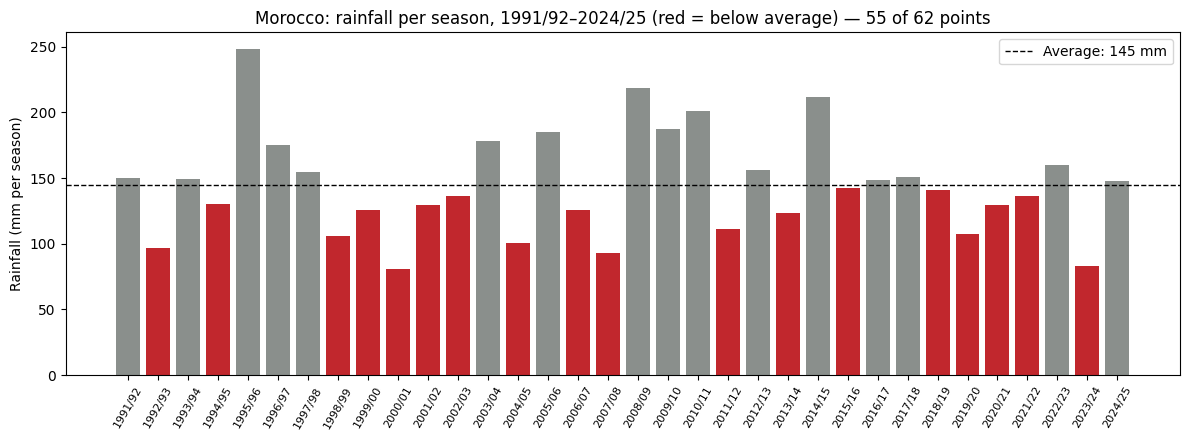

Driest seasons (% of average):
season
2000    56.0
2023    57.0
2007    64.0
1992    67.0
2004    69.0
1998    73.0
Name: precipitation_sum, dtype: float64


In [ ]:
import matplotlib.pyplot as plt

# Group days into rainy seasons: September to August (e.g. Sep 2022 – Aug 2023 = "2022/23")
rain["time"] = pd.to_datetime(rain["time"])
rain["season"] = rain["time"].dt.year.where(rain["time"].dt.month >= 9, rain["time"].dt.year - 1)
rain_full = rain[(rain.season >= 1991) & (rain.season <= 2024)]      # keep only complete seasons

# National rainfall per season = average of every grid point's seasonal total
season = rain_full.groupby(["lat", "lon", "season"]).precipitation_sum.sum().groupby("season").mean()
avg = season.mean()
pct = (season / avg * 100).round(0)

labels = [f"{s}/{str(s + 1)[2:]}" for s in season.index]
colors = ["#C1272D" if v < avg else "#8A8F8C" for v in season]

plt.figure(figsize=(12, 4.5))
plt.bar(labels, season, color=colors)
plt.axhline(avg, color="black", linestyle="--", linewidth=1, label=f"Average: {avg:.0f} mm")
plt.xticks(rotation=60, fontsize=8)
plt.ylabel("Rainfall (mm per season)")
plt.title("Morocco: rainfall per season, 1991/92–2024/25 (red = below average) — 55 of 62 points")
plt.legend()
plt.tight_layout()
plt.show()

print("Driest seasons (% of average):")
print(pct.sort_values().head(6))


Very wet seasons (25%+ above average):
         season    pct
season                
1995    1995/96  172.0
2005    2005/06  128.0
2008    2008/09  151.0
2009    2009/10  129.0
2010    2010/11  139.0
2014    2014/15  146.0
         period  seasons  15%+ wetter  25%+ wetter  35%+ wetter  below average
1991/92–2002/03       12            2            1            1              7
2003/04–2013/14       11            5            4            2              5
2014/15–2024/25       11            1            1            1              6


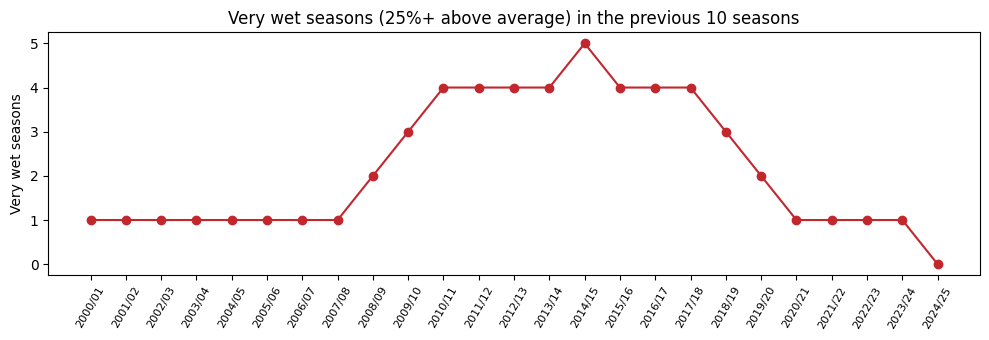

In [ ]:
# Which seasons were "very wet"? Check several thresholds, so the result doesn't depend on one choice
wet = pd.DataFrame({"season": labels, "pct": pct.values}, index=season.index)
print("Very wet seasons (25%+ above average):")
print(wet[wet.pct >= 125])

# Split the 34 seasons into three periods of about equal length
periods = {"1991/92–2002/03": (1991, 2002), "2003/04–2013/14": (2003, 2013), "2014/15–2024/25": (2014, 2024)}
rows = []
for name, (a, b) in periods.items():
    p = pct[(pct.index >= a) & (pct.index <= b)]
    rows.append({"period": name, "seasons": len(p),
                 "15%+ wetter": int((p >= 115).sum()),
                 "25%+ wetter": int((p >= 125).sum()),
                 "35%+ wetter": int((p >= 135).sum()),
                 "below average": int((p < 100).sum())})
print(pd.DataFrame(rows).to_string(index=False))

# Rolling window: in each 10-season window, how many seasons were 25%+ wetter than average?
rolling = (pct >= 125).astype(int).rolling(10).sum().dropna()
plt.figure(figsize=(10, 3.5))
plt.plot([f"{s}/{str(s + 1)[2:]}" for s in rolling.index], rolling.values, marker="o", color="#C1272D")
plt.xticks(rotation=60, fontsize=8)
plt.ylabel("Very wet seasons")
plt.title("Very wet seasons (25%+ above average) in the previous 10 seasons")
plt.tight_layout()
plt.show()


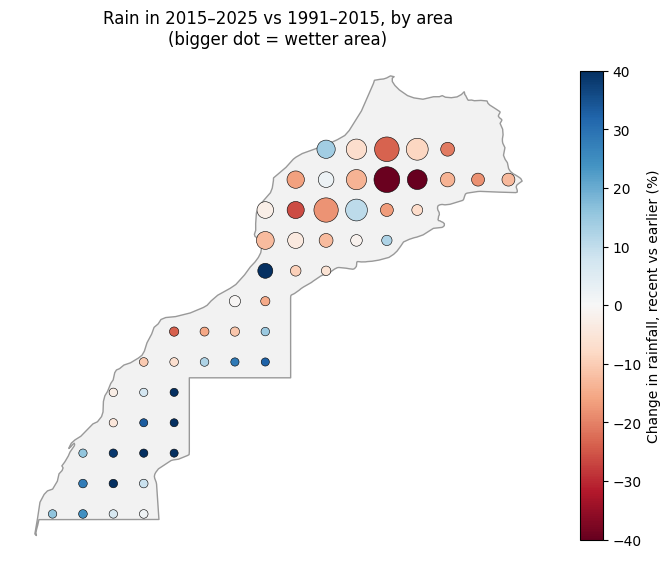

                    points  avg rain before (mm)  change (%)
region                                                      
South (below 29°N)    28.0                  37.0        13.5
Centre (29–33°N)      22.0                 239.0       -14.0
North (above 33°N)     5.0                 379.0       -10.2


/tmp/ipykernel_1476/370358269.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = change.groupby("region", observed=True).apply(


In [ ]:
# Seasonal rainfall per grid point
rain["time"] = pd.to_datetime(rain["time"])
rain["season"] = rain["time"].dt.year.where(rain["time"].dt.month >= 9, rain["time"].dt.year - 1)
pts = rain[(rain.season >= 1991) & (rain.season <= 2024)]
per_point = pts.groupby(["lat", "lon", "season"]).precipitation_sum.sum().reset_index()

# Compare recent seasons with earlier ones, point by point
before = per_point[per_point.season <= 2014].groupby(["lat", "lon"]).precipitation_sum.mean()
recent = per_point[per_point.season >= 2015].groupby(["lat", "lon"]).precipitation_sum.mean()
change = ((recent - before) / before * 100).rename("change_pct").reset_index()
change["before_mm"] = before.values.round(0)

# Map: red = lost rain, blue = gained rain
fig, ax = plt.subplots(figsize=(7, 7))
gpd.GeoSeries([morocco]).plot(ax=ax, color="#f2f2f2", edgecolor="#999999")
sc = ax.scatter(change.lon, change.lat, c=change.change_pct, cmap="RdBu", vmin=-40, vmax=40,
                s=change.before_mm / 2 + 20, edgecolors="black", linewidths=0.4)
plt.colorbar(sc, label="Change in rainfall, recent vs earlier (%)", shrink=0.7)
ax.set_title("Rain in 2015–2025 vs 1991–2015, by area\n(bigger dot = wetter area)")
ax.set_axis_off()
plt.tight_layout()
plt.show()

# Average change by region, weighting wetter areas more (that's where most of the water comes from)
change["region"] = pd.cut(change.lat, bins=[0, 29, 33, 40], labels=["South (below 29°N)", "Centre (29–33°N)", "North (above 33°N)"])
summary = change.groupby("region", observed=True).apply(
    lambda g: pd.Series({"points": len(g),
                         "avg rain before (mm)": g.before_mm.mean().round(0),
                         "change (%)": (g.change_pct * g.before_mm).sum() / g.before_mm.sum()}))
print(summary.round(1))


In [ ]:
missing = [p for p in grid if p not in set(zip(rain.lat, rain.lon))]
lats = ",".join(str(lat) for lat, lon in missing)
lons = ",".join(str(lon) for lat, lon in missing)
url = ("https://archive-api.open-meteo.com/v1/archive?"
       f"latitude={lats}&longitude={lons}&start_date=1991-01-01&end_date=2025-12-31"
       "&daily=precipitation_sum&timezone=Africa%2FCasablanca")
print(url)


https://archive-api.open-meteo.com/v1/archive?latitude=33.5,34.5,34.5,34.5,34.5,34.5,35.5&longitude=-2.5,-6.5,-5.5,-4.5,-3.5,-2.5,-5.5&start_date=1991-01-01&end_date=2025-12-31&daily=precipitation_sum&timezone=Africa%2FCasablanca


In [ ]:
import json, glob

missing = [p for p in grid if p not in set(zip(rain.lat, rain.lon))]
added = []
for fname in glob.glob("archive*.json"):
    with open(fname) as f:
        results = json.load(f)
    if isinstance(results, dict):
        continue
    for res in results:
        lat, lon = min(missing, key=lambda p: (p[0] - res["latitude"]) ** 2 + (p[1] - res["longitude"]) ** 2)
        d = pd.DataFrame(res["daily"])
        d["lat"], d["lon"] = lat, lon
        added.append(d)

rain = pd.concat([rain] + added)
rain["time"] = pd.to_datetime(rain["time"])
rain = rain.drop_duplicates(subset=["lat", "lon", "time"])
rain["year"] = rain["time"].dt.year
rain.to_csv("morocco_rain_grid.csv", index=False)
print(rain[["lat", "lon"]].drop_duplicates().shape[0], "of", len(grid), "points now in")


62 of 62 points now in


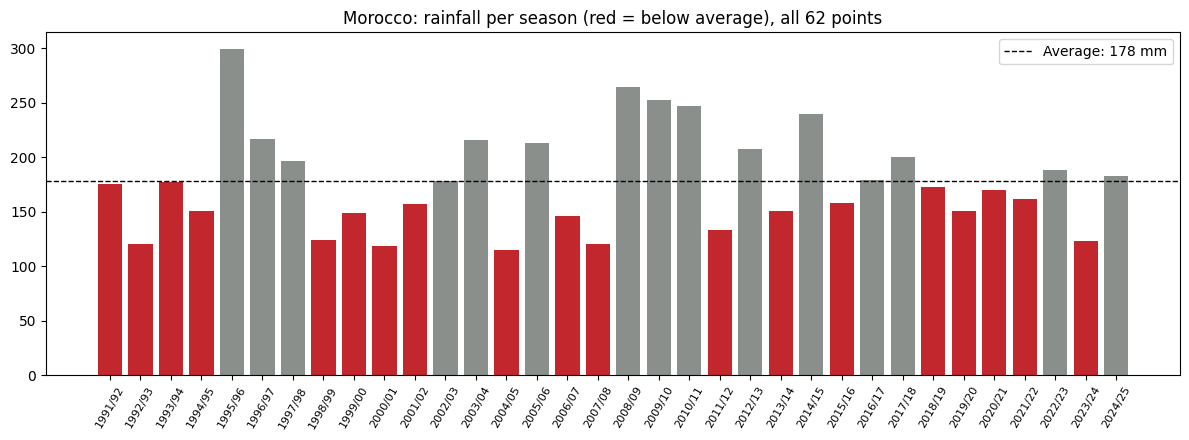

Driest seasons (% of average):
season
2004    65.0
2000    67.0
2007    67.0
1992    68.0
1998    69.0
Name: precipitation_sum, dtype: float64
Very wet seasons (25%+): ['1995/96', '2008/09', '2009/10', '2010/11', '2014/15']
1991-2002 | 25%+ wetter: 1 | 35%+ wetter: 1 | below avg: 8
2003-2013 | 25%+ wetter: 3 | 35%+ wetter: 3 | below avg: 5
2014-2024 | 25%+ wetter: 1 | 35%+ wetter: 0 | below avg: 6
Longest run without a very wet season: 12 seasons, ending 2007


In [ ]:
rain["season"] = rain["time"].dt.year.where(rain["time"].dt.month >= 9, rain["time"].dt.year - 1)
rain_full = rain[(rain.season >= 1991) & (rain.season <= 2024)]
per_point = rain_full.groupby(["lat", "lon", "season"]).precipitation_sum.sum().reset_index()
season = per_point.groupby("season").precipitation_sum.mean()
avg = season.mean()
pct = (season / avg * 100).round(0)
labels = [f"{s}/{str(s + 1)[2:]}" for s in season.index]

plt.figure(figsize=(12, 4.5))
plt.bar(labels, season, color=["#C1272D" if v < avg else "#8A8F8C" for v in season])
plt.axhline(avg, color="black", linestyle="--", linewidth=1, label=f"Average: {avg:.0f} mm")
plt.xticks(rotation=60, fontsize=8)
plt.title("Morocco: rainfall per season (red = below average), all 62 points")
plt.legend()
plt.tight_layout()
plt.show()

print("Driest seasons (% of average):")
print(pct.sort_values().head(5))
print("Very wet seasons (25%+):", [labels[i] for i, v in enumerate(pct) if v >= 125])

for name, (a, b) in {"1991-2002": (1991, 2002), "2003-2013": (2003, 2013), "2014-2024": (2014, 2024)}.items():
    p = pct[(pct.index >= a) & (pct.index <= b)]
    print(name, "| 25%+ wetter:", int((p >= 125).sum()), "| 35%+ wetter:", int((p >= 135).sum()), "| below avg:", int((p < 100).sum()))

streak, best, best_end = 0, 0, None
for s, v in pct.items():
    streak = 0 if v >= 125 else streak + 1
    if streak > best:
        best, best_end = streak, s
print("Longest run without a very wet season:", best, "seasons, ending", best_end)


South: 28 points | 37 mm before | +13.5% | +5.1 mm
Centre: 22 points | 239 mm before | -14.0% | -33.3 mm
North: 12 points | 416 mm before | -4.7% | -19.4 mm


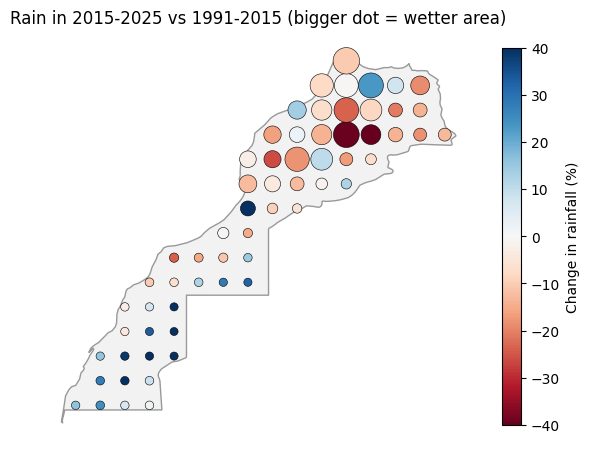

In [ ]:
before = per_point[per_point.season <= 2014].groupby(["lat", "lon"]).precipitation_sum.mean()
recent = per_point[per_point.season >= 2015].groupby(["lat", "lon"]).precipitation_sum.mean()
change = ((recent - before) / before * 100).rename("change_pct").reset_index()
change["before_mm"] = before.values
change["region"] = pd.cut(change.lat, bins=[0, 29, 33, 40], labels=["South", "Centre", "North"])

for region, g in change.groupby("region", observed=True):
    w_pct = (g.change_pct * g.before_mm).sum() / g.before_mm.sum()
    mm = (g.change_pct / 100 * g.before_mm).mean()
    print(f"{region}: {len(g)} points | {g.before_mm.mean():.0f} mm before | {w_pct:+.1f}% | {mm:+.1f} mm")

fig, ax = plt.subplots(figsize=(7, 7))
gpd.GeoSeries([morocco]).plot(ax=ax, color="#f2f2f2", edgecolor="#999999")
sc = ax.scatter(change.lon, change.lat, c=change.change_pct, cmap="RdBu", vmin=-40, vmax=40,
                s=change.before_mm / 2 + 20, edgecolors="black", linewidths=0.4)
plt.colorbar(sc, label="Change in rainfall (%)", shrink=0.7)
ax.set_title("Rain in 2015-2025 vs 1991-2015 (bigger dot = wetter area)")
ax.set_axis_off()
plt.show()


In [ ]:
print("Very wet seasons:")
for i, v in enumerate(pct):
    if v >= 125:
        print(" ", labels[i], int(v), "%")
print("Longest dry streak:", best, "seasons")
print("Ending in season:", best_end)
for region, g in change.groupby("region", observed=True):
    w = (g.change_pct * g.before_mm).sum() / g.before_mm.sum()
    mm = (g.change_pct / 100 * g.before_mm).mean()
    print(region, f"{w:+.1f}%", f"{mm:+.1f} mm")


Very wet seasons:
  1995/96 168 %
  2008/09 149 %
  2009/10 142 %
  2010/11 139 %
  2014/15 134 %
Longest dry streak: 12 seasons
Ending in season: 2007
South +13.5% +5.1 mm
Centre -14.0% -33.3 mm
North -4.7% -19.4 mm


In [ ]:
from scipy import stats

# National rainfall trend across all 34 seasons
r = stats.linregress(season.index, season.values)
sig = "significant" if r.pvalue < 0.05 else "not significant"
print(f"National rain trend: {r.slope * 10:+.1f} mm per decade, p = {r.pvalue:.3f} ({sig})")

# Is the recent decade different from before? (Welch t-test)
early = season.loc[1991:2014]
late = season.loc[2015:2024]
t = stats.ttest_ind(late, early, equal_var=False)
print(f"Average: {early.mean():.0f} mm (1991-2014) vs {late.mean():.0f} mm (2015-2024), p = {t.pvalue:.3f}")

# Same test per region
for region, g in change.groupby("region", observed=True):
    pts = per_point.merge(g[["lat", "lon"]], on=["lat", "lon"])
    reg = pts.groupby("season").precipitation_sum.mean()
    t = stats.ttest_ind(reg.loc[2015:2024], reg.loc[1991:2014], equal_var=False)
    print(f"{region}: {reg.loc[1991:2014].mean():.0f} -> {reg.loc[2015:2024].mean():.0f} mm, p = {t.pvalue:.3f}")


National rain trend: -0.4 mm per decade, p = 0.960 (not significant)
Average: 182 mm (1991-2014) vs 169 mm (2015-2024), p = 0.306
South: 37 -> 42 mm, p = 0.579
Centre: 239 -> 205 mm, p = 0.098
North: 416 -> 396 mm, p = 0.550


Yield data available: 1961 to 2024
33 seasons matched
Correlation: r = 0.61, p = 0.0001


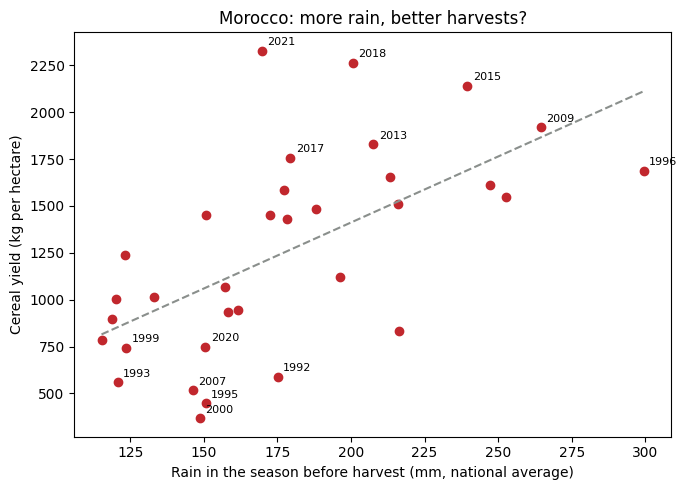

In [ ]:
import numpy as np
import requests
from scipy import stats

# Morocco's cereal yield (kg per hectare) from the World Bank
url = "https://api.worldbank.org/v2/country/MAR/indicator/AG.YLD.CREL.KG?format=json&per_page=100"
rows = requests.get(url, timeout=60).json()[1]
yld = pd.Series({int(r["date"]): r["value"] for r in rows if r["value"] is not None}).sort_index()
print("Yield data available:", yld.index.min(), "to", yld.index.max())

# Match each rainy season to the harvest that follows it (season 2022/23 -> harvest 2023)
df = pd.DataFrame({"rain": season.values}, index=season.index + 1)
df["yield"] = yld
df = df.dropna()

r = stats.pearsonr(df.rain, df["yield"])
print(f"{len(df)} seasons matched")
print(f"Correlation: r = {r.statistic:.2f}, p = {r.pvalue:.4f}")

plt.figure(figsize=(7, 5))
plt.scatter(df.rain, df["yield"], color="#C1272D")
for yr, row in df.iterrows():
    if row["yield"] < df["yield"].quantile(0.2) or row["yield"] > df["yield"].quantile(0.8):
        plt.annotate(str(yr), (row.rain, row["yield"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
fit = np.polyfit(df.rain, df["yield"], 1)
xs = np.linspace(df.rain.min(), df.rain.max(), 50)
plt.plot(xs, np.polyval(fit, xs), color="#8A8F8C", linestyle="--")
plt.xlabel("Rain in the season before harvest (mm, national average)")
plt.ylabel("Cereal yield (kg per hectare)")
plt.title("Morocco: more rain, better harvests?")
plt.tight_layout()
plt.show()


In [ ]:
import os

ET_FILE = "morocco_et0_grid.csv"
done = set()
if os.path.exists(ET_FILE):
    old = pd.read_csv(ET_FILE)
    done = set(zip(old.lat, old.lon))
print(len(done), "of", len(grid), "points already saved")

for lat, lon in grid:
    if (lat, lon) in done:
        continue
    params = {"latitude": lat, "longitude": lon,
              "start_date": "1991-01-01", "end_date": "2025-12-31",
              "daily": "et0_fao_evapotranspiration",
              "timezone": "Africa/Casablanca"}
    while True:
        url = "https://archive-api.open-meteo.com/v1/archive"
        data = requests.get(url, params=params, timeout=90).json()
        if "daily" in data:
            break
        print("Limited, waiting 5 min...")
        time.sleep(300)
    d = pd.DataFrame(data["daily"])
    d["lat"], d["lon"] = lat, lon
    d.to_csv(ET_FILE, mode="a", index=False,
             header=not os.path.exists(ET_FILE))
    done.add((lat, lon))
    print(len(done), "/", len(grid))
    time.sleep(8)

print("All evaporation data saved.")


0 of 62 points already saved
1 / 62
2 / 62
3 / 62
4 / 62
5 / 62
6 / 62
7 / 62
8 / 62
9 / 62
10 / 62
11 / 62
12 / 62
13 / 62
14 / 62
15 / 62
16 / 62
17 / 62
18 / 62
19 / 62
20 / 62
21 / 62
22 / 62
23 / 62
24 / 62
25 / 62
26 / 62
27 / 62
28 / 62
29 / 62
30 / 62
31 / 62
32 / 62
33 / 62
34 / 62
35 / 62
36 / 62
37 / 62
38 / 62
39 / 62
40 / 62
41 / 62
42 / 62
43 / 62
44 / 62
45 / 62
46 / 62
47 / 62
48 / 62
49 / 62
50 / 62
51 / 62
52 / 62
53 / 62
54 / 62
55 / 62
Limited, waiting 5 min...
Limited, waiting 5 min...
Limited, waiting 5 min...
Limited, waiting 5 min...


KeyboardInterrupt: 

In [ ]:
import json, glob

saved = pd.read_csv(ET_FILE)
have = set(zip(saved.lat, saved.lon))
need = [p for p in grid if p not in have]
print("Missing:", len(need))

for fname in glob.glob("archive*.json"):
    res_list = json.load(open(fname))
    if isinstance(res_list, dict):
        continue
    for res in res_list:
        if "et0_fao_evapotranspiration" not in res["daily"]:
            continue                      # skips the old rain files
        lat, lon = min(need, key=lambda p: (p[0] - res["latitude"]) ** 2 + (p[1] - res["longitude"]) ** 2)
        d = pd.DataFrame(res["daily"])
        d["lat"], d["lon"] = lat, lon
        d.to_csv(ET_FILE, mode="a", index=False, header=False)
        need.remove((lat, lon))
        print("Added", (lat, lon))

saved = pd.read_csv(ET_FILE)
print(saved[["lat", "lon"]].drop_duplicates().shape[0], "of", len(grid), "points saved")


In [ ]:
!pip install geopandas -q
import os, json, glob, time, requests
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
from google.colab import files

world = gpd.read_file("https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip")
shapes = world[world.ADMIN.isin(["Morocco", "Western Sahara"])].geometry
morocco = shapes.union_all() if hasattr(shapes, "union_all") else shapes.unary_union
grid = [(lat + 0.5, lon + 0.5) for lat in range(20, 36) for lon in range(-18, -1)
        if morocco.contains(Point(lon + 0.5, lat + 0.5))]
print(len(grid), "grid points")

files.upload()


62 grid points


In [6]:
done = set()
if os.path.exists(ET_FILE):
    old = pd.read_csv(ET_FILE)
    done = set(zip(old.lat, old.lon))
print(len(done), "of", len(grid), "points already saved")

for lat, lon in grid:
    if (lat, lon) in done:
        continue
    params = {"latitude": lat, "longitude": lon,
              "start_date": "1991-01-01", "end_date": "2025-12-31",
              "daily": "et0_fao_evapotranspiration",
              "timezone": "Africa/Casablanca"}
    while True:
        url = "https://archive-api.open-meteo.com/v1/archive"
        data = requests.get(url, params=params, timeout=90).json()
        if "daily" in data:
            break
        print("Limited, waiting 5 min...")
        time.sleep(300)
    d = pd.DataFrame(data["daily"])
    d["lat"], d["lon"] = lat, lon
    d.to_csv(ET_FILE, mode="a", index=False, header=False)
    done.add((lat, lon))
    print(len(done), "/", len(grid))
    time.sleep(8)

print("All evaporation data saved.")
files.download(ET_FILE)


7 of 62 points already saved
8 / 62
9 / 62
10 / 62
11 / 62
12 / 62
13 / 62
14 / 62
15 / 62
16 / 62
17 / 62
18 / 62
19 / 62
20 / 62
21 / 62
22 / 62
23 / 62
24 / 62
25 / 62
26 / 62
27 / 62
28 / 62
29 / 62
30 / 62
31 / 62
32 / 62
33 / 62
34 / 62
35 / 62
36 / 62
37 / 62
38 / 62
39 / 62
40 / 62
41 / 62
42 / 62
43 / 62
44 / 62
45 / 62
46 / 62
47 / 62
48 / 62
49 / 62
50 / 62
51 / 62
52 / 62
53 / 62
54 / 62
55 / 62
56 / 62
57 / 62
58 / 62
59 / 62
60 / 62
61 / 62
62 / 62
All evaporation data saved.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

62 evaporation points

Trend per decade (p < 0.05 = significant):
rain: -0.4 mm, p = 0.960
et0: +31.2 mm, p = 0.001
balance: -31.6 mm, p = 0.047

Average per season, 1991-2014 vs 2015-2024:
rain: 182 -> 169 mm
et0: 1989 -> 2048 mm
balance: -1807 -> -1879 mm


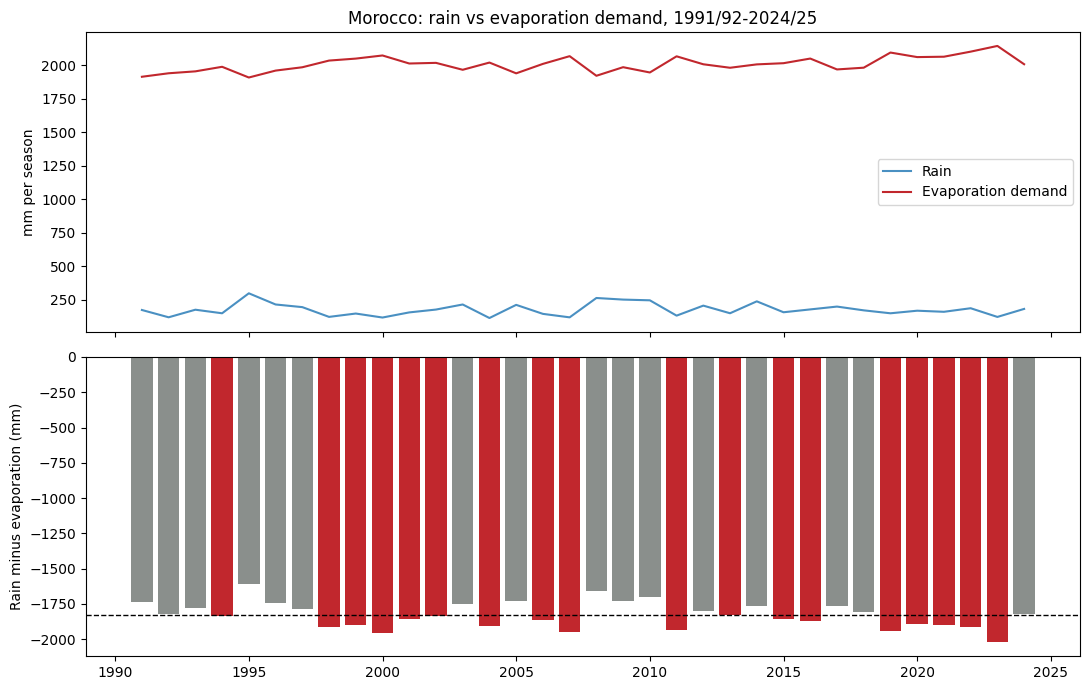

In [8]:
from scipy import stats

et = pd.read_csv(ET_FILE)
et["time"] = pd.to_datetime(et["time"])
et = et.drop_duplicates(subset=["lat", "lon", "time"])
print(et[["lat", "lon"]].drop_duplicates().shape[0], "evaporation points")

both = rain.merge(et, on=["lat", "lon", "time"])
mo, yr = both["time"].dt.month, both["time"].dt.year
both["season"] = yr.where(mo >= 9, yr - 1)
both = both[(both.season >= 1991) & (both.season <= 2024)]

pp = both.groupby(["lat", "lon", "season"])[["precipitation_sum", "et0_fao_evapotranspiration"]].sum()
pp["balance"] = pp.precipitation_sum - pp.et0_fao_evapotranspiration
nat = pp.groupby("season").mean()
nat.columns = ["rain", "et0", "balance"]

print("\nTrend per decade (p < 0.05 = significant):")
for col in ["rain", "et0", "balance"]:
    r = stats.linregress(nat.index, nat[col])
    print(f"{col}: {r.slope * 10:+.1f} mm, p = {r.pvalue:.3f}")

early, late = nat.loc[1991:2014].mean(), nat.loc[2015:2024].mean()
print("\nAverage per season, 1991-2014 vs 2015-2024:")
for col in ["rain", "et0", "balance"]:
    print(f"{col}: {early[col]:.0f} -> {late[col]:.0f} mm")

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(nat.index, nat.rain, color="#4a90c2", label="Rain")
ax[0].plot(nat.index, nat.et0, color="#C1272D", label="Evaporation demand")
ax[0].set_ylabel("mm per season")
ax[0].legend()
ax[0].set_title("Morocco: rain vs evaporation demand, 1991/92-2024/25")
colors = ["#C1272D" if v < nat.balance.mean() else "#8A8F8C" for v in nat.balance]
ax[1].bar(nat.index, nat.balance, color=colors)
ax[1].axhline(nat.balance.mean(), color="black", linestyle="--", linewidth=1)
ax[1].set_ylabel("Rain minus evaporation (mm)")
plt.tight_layout()
plt.show()


In [9]:
import json
from scipy import stats

mo, yr = rain["time"].dt.month, rain["time"].dt.year
rain["season"] = yr.where(mo >= 9, yr - 1)
r2 = rain[(rain.season >= 1991) & (rain.season <= 2024)]
pp_rain = r2.groupby(["lat", "lon", "season"]).precipitation_sum.sum().reset_index()

before = pp_rain[pp_rain.season <= 2014].groupby(["lat", "lon"]).precipitation_sum.mean()
recent = pp_rain[pp_rain.season >= 2015].groupby(["lat", "lon"]).precipitation_sum.mean()
points = pd.DataFrame({"before": before, "recent": recent}).reset_index()
points["change"] = (points.recent - points.before) / points.before * 100

seasons = nat.reset_index()
print(len(points), "points,", len(seasons), "seasons")


62 points, 34 seasons


In [10]:
url = "https://api.worldbank.org/v2/country/MAR/indicator/AG.YLD.CREL.KG?format=json&per_page=100"
rows = requests.get(url, timeout=60).json()[1]
yld = {int(r["date"]): r["value"] for r in rows if r["value"]}

trend = {}
for col in ["rain", "et0", "balance"]:
    t = stats.linregress(nat.index, nat[col])
    trend[col] = {"slope": round(t.slope * 10, 1), "p": round(t.pvalue, 3)}

out = {
  "seasons": [{"season": int(s.season), "rain": round(s.rain, 1),
               "et0": round(s.et0, 1), "harvest": yld.get(int(s.season) + 1)}
              for s in seasons.itertuples()],
  "points": [{"lat": p.lat, "lon": p.lon, "before": round(p.before, 1),
              "recent": round(p.recent, 1), "change": round(p.change, 1)}
             for p in points.itertuples()],
  "trend": trend,
}
json.dump(out, open("rain_data.json", "w"))
files.download("rain_data.json")
print("Saved:", trend)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved: {'rain': {'slope': np.float64(-0.4), 'p': np.float64(0.96)}, 'et0': {'slope': np.float64(31.2), 'p': np.float64(0.001)}, 'balance': {'slope': np.float64(-31.6), 'p': np.float64(0.047)}}
